# Notebook 13 - Alur Penuh: Data Mentah -> Best Configuration (FinBERT-LSTM)

Notebook ini merangkum **seluruh alur penelitian** dari data mentah sampai model
terlatih dengan hyperparameter terbaik, dalam SATU notebook yang bisa dijalankan
urut dari atas ke bawah:

1. Load data mentah (headline + OHLCV)
2. FinBERT Scoring (per-headline)
3. Agregasi menjadi sentimen harian
4. Merge OHLCV + `sentiment_mean`
5. Stasioner-kan data (return features, pct_change)
6. Splitting data (kronologis 70/15/15) + windowing
7. Training memakai **Best Configuration** hasil Random Search (Notebook 07)

**Prinsip: reuse komponen produksi, bukan reimplement.** Setiap tahap memanggil
modul produksi yang sama dipakai API (`pipeline/preprocessing/*`,
`pipeline/feature_engineering/dataset_builder.py`,
`models/lstm/notebook07_common.py`) — supaya hasil notebook ini SELALU konsisten
dengan apa yang dijalankan sistem sungguhan, bukan implementasi paralel yang bisa
menyimpang diam-diam.

**Scope data:** `STOCK_DATA_RANGE=2018_2024` (default project, sama dengan yang
dipakai Notebook 07/08 — Batasan Masalah BAB I). Horizon prediksi = 5 hari,
window = 20 hari — mengikuti keputusan project 2026-07-28 (lihat `CLAUDE.md`).

**Artefak yang dihasilkan notebook ini disimpan TERISOLASI**
(prefix `notebook13_full_pipeline_*`) — TIDAK menimpa artefak resmi
(`finbert_lstm_skripsi.*`) yang dipakai halaman Prediction di UI.

## Setup

In [144]:
from __future__ import annotations

import json
import logging
import sys
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path("E:/forecasting_index_snp500/stock_prediction")
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)

logging.basicConfig(level=logging.INFO, format="%(asctime)s  %(levelname)-8s  %(message)s", datefmt="%H:%M:%S")
logger = logging.getLogger("notebook13")

RAW_HEADLINES_CSV = ROOT / "data/raw/news/sp500_headlines_2018_2024.csv"
RAW_OHLCV_CSV = ROOT / "data/raw/stocks/GSPC_2018_2024.csv"
FINBERT_PATH = str(ROOT / "models/finbert/models--ProsusAI--finbert")

OUT_DIR = ROOT / "data/processed/notebook13_full_pipeline"
OUT_DIR.mkdir(parents=True, exist_ok=True)

ARTIFACT_DIR = ROOT / "data/artifacts/lstm_weights"
BEST_CONFIG_METADATA = ARTIFACT_DIR / "finbert_lstm_skripsi_metadata.json"

WINDOW = 20
HORIZON = 5
NEUTRAL_BAND = 0.05
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
logger.info("Device: %s", device)

02:58:58  INFO      Device: cuda


## Bagian 1 - Load Data Mentah

Dua sumber data mentah:
- **Headline berita**: `data/raw/news/sp500_headlines_2018_2024.csv` (kolom `Title`, `Date`)
- **OHLCV S&P 500 (^GSPC)**: `data/raw/stocks/GSPC_2018_2024.csv` (kolom `Date, Open, High, Low, Close, Volume, Dividends, Stock Splits`)

In [145]:
df_headlines_raw = pd.read_csv(RAW_HEADLINES_CSV)
df_ohlcv_raw = pd.read_csv(RAW_OHLCV_CSV, parse_dates=["Date"])

print(f"Headline mentah : {len(df_headlines_raw):,} baris")
print(f"OHLCV mentah    : {len(df_ohlcv_raw):,} baris ({df_ohlcv_raw['Date'].min().date()} s/d {df_ohlcv_raw['Date'].max().date()})")
display(df_headlines_raw.head())
display(df_ohlcv_raw.head())

Headline mentah : 13,422 baris
OHLCV mentah    : 1,552 baris (2018-01-02 s/d 2024-03-04)


,Title,Date
0,2018 Stock Market Cycles Outlook: New Highs......,2018-01-02
1,The Surprising Outperformance Of A Value-Tilte...,2018-01-02
2,This Day In Market History: NYSE Volume Hits 2...,2018-01-02
3,These 4 S&P 500 Stocks Doubled in 2017,2018-01-02
4,Warren Buffett wins $1M bet against hedge fund...,2018-01-02


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000,0.0,0.0
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000,0.0,0.0
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000,0.0,0.0
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000,0.0,0.0
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000,0.0,0.0


## Bagian 2 - Clean Headline

Membersihkan teks headline sebelum masuk FinBERT: strip whitespace, buang baris
kosong/duplikat (`Title`+`Date`), buang headline < 3 kata (noise, tidak
informatif untuk sentimen). Metodologi sama dengan Notebook 02 dan
`scripts/process_new_scraped_data.py`.

In [146]:
def clean_headlines(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["Title"] = df["Title"].astype(str).str.strip()

    before = len(df)
    df = df[df["Title"].notna() & (df["Title"] != "") & (df["Title"] != "nan")]
    logger.info("Drop kosong: %d -> %d", before, len(df))

    before = len(df)
    df = df.drop_duplicates(subset=["Title", "Date"])
    logger.info("Drop duplikat: %d -> %d", before, len(df))

    before = len(df)
    df = df[df["Title"].str.split().str.len() >= 3]
    logger.info("Filter <3 kata: %d -> %d", before, len(df))

    return df.reset_index(drop=True)


df_headlines_clean = clean_headlines(df_headlines_raw)
print(f"Headline setelah cleaning: {len(df_headlines_clean):,} baris")
df_headlines_clean.head()

02:58:58  INFO      Drop kosong: 13422 -> 13422
02:58:58  INFO      Drop duplikat: 13422 -> 12467
02:58:58  INFO      Filter <3 kata: 12467 -> 12455


Headline setelah cleaning: 12,455 baris


,Title,Date
0,2018 Stock Market Cycles Outlook: New Highs......,2018-01-02
1,The Surprising Outperformance Of A Value-Tilte...,2018-01-02
2,This Day In Market History: NYSE Volume Hits 2...,2018-01-02
3,These 4 S&P 500 Stocks Doubled in 2017,2018-01-02
4,Warren Buffett wins $1M bet against hedge fund...,2018-01-02


## Bagian 3 - FinBERT Scoring

Menjalankan inferensi FinBERT (`ProsusAI/finbert`) per headline via
`TextPreprocessor` (komponen produksi yang sama dipakai endpoint
`POST /api/v1/sentiment/pipeline/run`). Output: `sentiment_label`
(positive/neutral/negative), `sentiment_score` (confidence 0-1),
`sentiment_numeric` (+1/0/-1).

> Catatan: cell ini menjalankan inferensi model atas seluruh headline
> (~ribuan baris) — bisa memakan waktu beberapa menit di CPU, jauh lebih cepat
> di GPU (device dipilih otomatis di atas).

In [147]:
from pipeline.preprocessing.text_preprocessor import TextPreprocessor

hf_device = 0 if torch.cuda.is_available() else -1
preprocessor = TextPreprocessor(model_path=FINBERT_PATH, batch_size=32, device=hf_device)

df_scored = preprocessor.extract_sentiment_scores(df_headlines_clean, text_column="Title")

print("Distribusi label sentimen:")
print(df_scored["sentiment_label"].value_counts())
df_scored.head()

02:58:58  INFO      Loading FinBERT model from E:\forecasting_index_snp500\stock_prediction\models\finbert\models--ProsusAI--finbert
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 8298.36it/s]
02:59:14  INFO      Extracted sentiment scores for 12455 records


Distribusi label sentimen:
sentiment_label
neutral     6233
negative    3565
positive    2657
Name: count, dtype: int64


,Title,Date,sentiment_label,sentiment_score,sentiment_numeric
0,2018 Stock Market Cycles Outlook: New Highs......,2018-01-02,positive,0.873103,1
1,The Surprising Outperformance Of A Value-Tilte...,2018-01-02,positive,0.940940,1
2,This Day In Market History: NYSE Volume Hits 2...,2018-01-02,neutral,0.804172,0
3,These 4 S&P 500 Stocks Doubled in 2017,2018-01-02,positive,0.726535,1
4,Warren Buffett wins $1M bet against hedge fund...,2018-01-02,neutral,0.815192,0


## Bagian 4 - Agregasi Menjadi Sentimen Harian

Beberapa headline per hari diagregasi menjadi 1 nilai `sentiment_mean` per
tanggal, memakai metode **probability-weighted** (`signed_score = sentiment_numeric
x sentiment_score`, lalu dirata-rata per hari) — metode yang sama dengan
`scripts/regenerate_sentiment_weighted.py` (dipakai meregenerasi
`headlines_daily_sentiment.csv` resmi).

In [148]:
def aggregate_daily(df_scored: pd.DataFrame, neutral_band: float = NEUTRAL_BAND) -> pd.DataFrame:
    df = df_scored.copy()
    df["signed_score"] = df["sentiment_numeric"] * df["sentiment_score"]
    grp = df.groupby("Date")

    daily = pd.DataFrame()
    daily["headline_count"] = grp["Title"].count()
    daily["sentiment_mean"] = grp["signed_score"].mean().round(6)

    def prop(g, label):
        return (g == label).sum() / len(g) if len(g) > 0 else 0.0

    daily["sentiment_pos"] = grp["sentiment_label"].apply(lambda g: prop(g, "positive")).round(6)
    daily["sentiment_neg"] = grp["sentiment_label"].apply(lambda g: prop(g, "negative")).round(6)
    daily["sentiment_neu"] = grp["sentiment_label"].apply(lambda g: prop(g, "neutral")).round(6)
    daily["sentiment_label"] = daily["sentiment_mean"].apply(
        lambda v: "neutral" if abs(v) < neutral_band else ("positive" if v > 0 else "negative")
    )

    daily = daily.reset_index()
    daily["Date"] = pd.to_datetime(daily["Date"])
    return daily.sort_values("Date").reset_index(drop=True)


df_daily_sentiment = aggregate_daily(df_scored)
daily_sentiment_path = OUT_DIR / "notebook13_daily_sentiment.csv"
df_daily_sentiment.to_csv(daily_sentiment_path, index=False)

print(f"Sentimen harian: {len(df_daily_sentiment):,} hari unik -> disimpan ke {daily_sentiment_path}")
df_daily_sentiment.head()

Sentimen harian: 1,528 hari unik -> disimpan ke E:\forecasting_index_snp500\stock_prediction\data\processed\notebook13_full_pipeline\notebook13_daily_sentiment.csv


,Date,headline_count,sentiment_mean,sentiment_pos,sentiment_neg,sentiment_neu,sentiment_label
0,2018-01-02,9,0.311223,0.555556,0.111111,0.333333,positive
1,2018-01-03,6,-0.018505,0.166667,0.333333,0.500000,neutral
2,2018-01-04,2,0.000000,0.000000,0.000000,1.000000,neutral
3,2018-01-05,2,0.071510,0.500000,0.500000,0.000000,positive
4,2018-01-08,6,0.152372,0.166667,0.000000,0.833333,positive


## Bagian 5 - Clean OHLCV

Membersihkan OHLCV mentah via `StockPreprocessor` (komponen produksi yang sama
dipakai pipeline resmi): buang kolom tak relevan (`Dividends`, `Stock Splits`),
validasi kolom wajib, sort by Date, buang duplikat tanggal, isi NaN
(forward-fill -> backward-fill), validasi nilai (harga > 0, volume >= 0).

In [149]:
from pipeline.preprocessing.stock_preprocessor import StockPreprocessor

sp = StockPreprocessor()
df_ohlcv_clean = sp.clean(df_ohlcv_raw)

print(f"OHLCV bersih: {len(df_ohlcv_clean):,} baris ({df_ohlcv_clean['Date'].min().date()} s/d {df_ohlcv_clean['Date'].max().date()})")
df_ohlcv_clean.head()

02:59:15  INFO      ============================================================
02:59:15  INFO      MULAI CLEANING — 1552 baris input
02:59:15  INFO      ============================================================
02:59:15  INFO      Kolom dihapus: ['Dividends', 'Stock Splits']
02:59:15  INFO      Validasi kolom OHLCV: OK — ['Open', 'High', 'Low', 'Close', 'Volume']
02:59:15  INFO      Data diurutkan berdasarkan Date (ascending).
02:59:15  INFO      Tidak ada duplikat tanggal ditemukan.
02:59:15  INFO      Tidak ada NaN pada kolom OHLCV.
02:59:15  INFO      Validasi nilai OHLCV: semua 1552 baris valid.
02:59:15  INFO      CLEANING SELESAI — 1552 baris | 6 kolom | rentang: 2018-01-02 s/d 2024-03-04
02:59:15  INFO      ============================================================


OHLCV bersih: 1,552 baris (2018-01-02 s/d 2024-03-04)


,Date,Open,High,Low,Close,Volume
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000


## Bagian 6 - Merge OHLCV + Sentimen Harian

Inner join OHLCV bersih dengan sentimen harian pada kolom `Date` — hanya hari
yang punya KEDUA data (hari trading DAN ada headline) yang dipertahankan.

In [150]:
df_joined = pd.merge(
    df_ohlcv_clean[["Date", "Open", "High", "Low", "Close", "Volume"]],
    df_daily_sentiment[["Date", "sentiment_mean"]],
    on="Date",
    how="inner",
).sort_values("Date").reset_index(drop=True)

joined_path = OUT_DIR / "notebook13_joined_ohlcv_sentiment.csv"
df_joined.to_csv(joined_path, index=False)

print(f"Joined: {len(df_joined):,} baris ({df_joined['Date'].min().date()} s/d {df_joined['Date'].max().date()}) -> {joined_path}")
df_joined.head()

Joined: 1,528 baris (2018-01-02 s/d 2024-03-04) -> E:\forecasting_index_snp500\stock_prediction\data\processed\notebook13_full_pipeline\notebook13_joined_ohlcv_sentiment.csv


,Date,Open,High,Low,Close,Volume,sentiment_mean
0,2018-01-02,2683.729980,2695.889893,2682.360107,2695.810059,3397430000,0.311223
1,2018-01-03,2697.850098,2714.370117,2697.770020,2713.060059,3544030000,-0.018505
2,2018-01-04,2719.310059,2729.290039,2719.070068,2723.989990,3697340000,0.000000
3,2018-01-05,2731.330078,2743.449951,2727.919922,2743.149902,3239280000,0.071510
4,2018-01-08,2742.669922,2748.510010,2737.600098,2747.709961,3246160000,0.152372


## Bagian 7 - Stasioner-kan Data (Return Features)

Kolom harga level (`Open/High/Low/Close`) bersifat NON-STASIONER (terus naik
sepanjang waktu) — temuan Notebook 11 menunjukkan ini menyebabkan sebagian
data test ter-scaling di luar rentang [0,1] dan korelasi fitur-label berbalik
tanda train->test. Solusinya (Notebook 12): ganti fitur harga level dengan
**return harian** (`pct_change`), yang stasioner. `Close` level tetap
disertakan (bukan sebagai fitur, tapi untuk menghitung label horizon
`Close[t+H] > Close[t]` pada tahap splitting).

In [151]:
df_stationary = df_joined.copy()
df_stationary["ret_open"] = df_stationary["Open"].pct_change()
df_stationary["ret_high"] = df_stationary["High"].pct_change()
df_stationary["ret_low"] = df_stationary["Low"].pct_change()
df_stationary["ret_close"] = df_stationary["Close"].pct_change()
df_stationary["ret_volume"] = df_stationary["Volume"].pct_change()

RETURN_COLS = ["ret_open", "ret_high", "ret_low", "ret_close", "ret_volume"]

# inf (dari hari dengan Volume=0) -> NaN -> dibuang (bukan diisi 0)
df_stationary[RETURN_COLS] = df_stationary[RETURN_COLS].replace([np.inf, -np.inf], np.nan)
df_stationary = df_stationary.dropna(subset=RETURN_COLS).reset_index(drop=True)

df_stationary = df_stationary[["Date", *RETURN_COLS, "sentiment_mean", "Close"]]

stationary_path = OUT_DIR / "notebook13_return_features_stationary.csv"
df_stationary.to_csv(stationary_path, index=False)

print(f"Data stasioner: {len(df_stationary):,} baris ({df_stationary['Date'].min().date()} s/d {df_stationary['Date'].max().date()}) -> {stationary_path}")
df_stationary.head()

Data stasioner: 1,526 baris (2018-01-03 s/d 2024-03-04) -> E:\forecasting_index_snp500\stock_prediction\data\processed\notebook13_full_pipeline\notebook13_return_features_stationary.csv


,Date,ret_open,ret_high,ret_low,ret_close,ret_volume,sentiment_mean,Close
0,2018-01-03,0.005261,0.006855,0.005745,0.006399,0.043150,-0.018505,2713.060059
1,2018-01-04,0.007954,0.005497,0.007895,0.004029,0.043259,0.000000,2723.989990
2,2018-01-05,0.004420,0.005188,0.003255,0.007034,-0.123889,0.071510,2743.149902
3,2018-01-08,0.004152,0.001844,0.003549,0.001662,0.002124,0.152372,2747.709961
4,2018-01-09,0.003092,0.003868,0.003748,0.001303,0.068173,0.551667,2751.290039


### Sanity check — bandingkan dengan pipeline produksi

`pipeline/feature_engineering/dataset_builder.py::load_return_features()`
menghasilkan data yang SEHARUSNYA identik (dibaca dari
`data/processed/stocks/GSPC_2018_2024.csv` +
`data/processed/sentiment/headlines_daily_sentiment.csv` resmi, yang secara
metodologis dibangun dengan cara yang sama seperti Bagian 1-7 di atas).
Perbandingan ini memverifikasi bahwa alur raw-to-stationary di notebook ini
BENAR-BENAR mereplikasi pipeline produksi, bukan implementasi paralel yang
menyimpang.

In [152]:
from pipeline.feature_engineering.dataset_builder import load_return_features

df_production = load_return_features()

common_dates = set(df_stationary["Date"]) & set(df_production["Date"])
print(f"Baris notebook13   : {len(df_stationary):,}")
print(f"Baris produksi     : {len(df_production):,}")
print(f"Tanggal beririsan  : {len(common_dates):,}")

merged_check = pd.merge(
    df_stationary, df_production,
    on="Date", suffixes=("_nb13", "_prod"),
)
for col in RETURN_COLS:
    diff = (merged_check[f"{col}_nb13"] - merged_check[f"{col}_prod"]).abs()
    print(f"  max|diff| {col:12s}: {diff.max():.10f}")

02:59:15  INFO      Stock loaded: 1552 rows (2018-01-02 – 2024-03-04)
02:59:15  INFO      Sentiment loaded: 1528 rows (2018-01-02 – 2024-03-04)


02:59:15  INFO      Joined dataset: 1528 rows (2018-01-02 – 2024-03-04)
02:59:15  INFO      Return-features dataset: 1526 rows (2018-01-03 – 2024-03-04)


Baris notebook13   : 1,526
Baris produksi     : 1,526
Tanggal beririsan  : 1,526
  max|diff| ret_open    : 0.0000000000
  max|diff| ret_high    : 0.0000000000
  max|diff| ret_low     : 0.0000000000
  max|diff| ret_close   : 0.0000000000
  max|diff| ret_volume  : 0.0000000000


## Bagian 8 - Splitting Data + Windowing

Reuse langsung `models/lstm/notebook07_common.py` (modul produksi, dipakai
Random Search Notebook 07 & API `/train/skripsi/*`):

1. **Label**: `Close[t+HORIZON] > Close[t]` (horizon=5 hari)
2. **Split kronologis persentase** 70% train / 15% val / 15% test (TANPA
   shuffle antar waktu — mencegah data leakage temporal)
3. **Capping outlier IQR** (fit HANYA di train, diterapkan ke val/test)
4. **Scaling** `MinMaxScaler` (fit HANYA di train — anti-leakage)
5. **Windowing** (window=20 hari) -> `(X, y)` siap masuk LSTM

`load_data_fn` diarahkan ke `df_stationary` yang sudah dibangun dari data
mentah di Bagian 1-7 di atas (bukan baca ulang dari file produksi) — supaya
notebook ini benar-benar end-to-end dari raw data.

In [153]:
from pipeline.feature_engineering.dataset_builder import RETURN_FEATURE_COLS_B
from models.lstm.notebook07_common import prepare_dataset_bundle

FEATURE_COLS = RETURN_FEATURE_COLS_B  # ret_open/high/low/close/volume + sentiment_mean
CAPPING_COLS = RETURN_FEATURE_COLS_B

def load_data_fn() -> pd.DataFrame:
    return df_stationary.copy()

bundle = prepare_dataset_bundle(
    load_data_fn,
    capping_cols=CAPPING_COLS,
    feature_cols=FEATURE_COLS,
    horizon=HORIZON,
    train_ratio=0.70,
    val_ratio=0.15,
    window=WINDOW,
)

print("Split sizes:", bundle.split_sizes)
print("n_capped   :", bundle.n_capped)
print("X_train:", bundle.X_train.shape, "| X_val:", bundle.X_val.shape, "| X_test:", bundle.X_test.shape)
print("mean y_train: %.4f | mean y_val: %.4f | mean y_test: %.4f" % (
    bundle.y_train.mean(), bundle.y_val.mean(), bundle.y_test.mean(),
))

Split sizes: {'train_rows': 1064, 'val_rows': 228, 'test_rows': 229, 'train_samples': 1045, 'val_samples': 209, 'test_samples': 210}
n_capped   : {'train': {'ret_open': 80, 'ret_high': 87, 'ret_low': 67, 'ret_close': 65, 'ret_volume': 76, 'sentiment_mean': 36}, 'val': {'ret_open': 32, 'ret_high': 44, 'ret_low': 25, 'ret_close': 30, 'ret_volume': 17, 'sentiment_mean': 0}, 'test': {'ret_open': 0, 'ret_high': 6, 'ret_low': 0, 'ret_close': 0, 'ret_volume': 17, 'sentiment_mean': 1}}
X_train: (1045, 20, 6) | X_val: (209, 20, 6) | X_test: (210, 20, 6)
mean y_train: 0.6172 | mean y_val: 0.5359 | mean y_test: 0.6476


## Bagian 9 - Best Configuration (Random Search Notebook 07)

Hyperparameter terbaik dibaca **langsung** dari
`data/artifacts/lstm_weights/finbert_lstm_skripsi_metadata.json` (hasil Random
Search 20 iterasi Notebook 07, dipilih via F1-macro + threshold sweep pada
val-set) — BUKAN di-hardcode, supaya notebook ini otomatis ikut ter-update
kalau Notebook 07 dijalankan ulang.

In [154]:
with open(BEST_CONFIG_METADATA, encoding="utf-8") as f:
    official_metadata = json.load(f)

official_config = official_metadata["config"]
print("Best Configuration (Random Search Notebook 07) - REFERENSI SAJA:")
for k, v in official_config.items():
    print(f"  {k:12s}: {v}")

print("\nCatatan: config ini TIDAK langsung dipakai training di bawah -"
      " lihat Bagian 9b untuk alasan & perbaikannya.")

print(f"\nwindow            : {official_metadata['window']}")
print(f"horizon           : {official_metadata['horizon']}")
print(f"feature_cols      : {official_metadata['feature_cols']}")
print(f"best_val_f1_macro : {official_metadata['best_val_f1_macro']}")
print(f"trained_at        : {official_metadata['trained_at']}")

assert official_metadata["window"] == WINDOW
assert official_metadata["horizon"] == HORIZON
assert official_metadata["feature_cols"] == FEATURE_COLS

Best Configuration (Random Search Notebook 07) - REFERENSI SAJA:
  hidden_size : 128
  num_layers  : 1
  dropout     : 0.39857495441806856
  optimizer   : adam
  activation  : tanh
  lr          : 0.0003653993614279478
  epochs      : 50
  batch_size  : 64

Catatan: config ini TIDAK langsung dipakai training di bawah - lihat Bagian 9b untuk alasan & perbaikannya.

window            : 20
horizon           : 5
feature_cols      : ['ret_open', 'ret_high', 'ret_low', 'ret_close', 'ret_volume', 'sentiment_mean']
best_val_f1_macro : 0.582246
trained_at        : 2026-07-31T10:53:53.790850+00:00


### Bagian 9b - Perbaikan Resep Training (berbasis bukti diagnostik)

Menjalankan Bagian 10 dengan `official_config` Notebook 07 apa adanya
(`hidden_size=128, num_layers=1, dropout=0.399, lr=3.65e-4`) menghasilkan
`train_loss` turun (0.70->0.66) sementara `val_loss` stagnan di ~0.69.
Pola itu awalnya dibaca sebagai *overfitting*, lalu direspons dengan tiga rem
sekaligus: `num_layers>=2` + dropout 0.2-0.5 + `weight_decay=1e-4` + early
stopping `patience=7` yang memantau `val_loss`.

**Respons itu terlalu keras, dan justru mematikan proses belajarnya.** Dengan
resep tersebut, 18 dari 20 iterasi Random Search berhenti pada
`val_f1_macro = 0.3489` yang identik - nilai yang persis sama dengan model
yang selalu menebak satu kelas (proporsi 'up' di val = 0.5359, sehingga
F1 kelas 'up' = 0.6978 dan F1-macro = 0.3489). Confusion matrix Bagian 13
mengkonfirmasi: `tn=0` dan `fn=0` untuk ketiga rasio split - model tidak
pernah sekalipun mengeluarkan 'down'.

#### Diagnosis (dua uji terpisah)

**Uji kapasitas.** Model yang sama dilatih ulang tanpa regularisasi apa pun
pada 1045 sampel train: `train_loss` turun 0.6875 -> **0.0454** dengan
akurasi 98.76%. Model ini SANGAT mampu belajar dari data ini - jadi angka
0.693 yang mentok bukan disebabkan bug, windowing yang salah, atau gradien
yang mati, melainkan oleh resep training-nya sendiri. Dengan regularisasi
lama, model baru keluar dari lantai acak setelah **epoch ~150**, sementara
early stopping memotongnya di **epoch 8-10**.

**Uji baseline.** Regresi logistik biasa pada fitur yang SAMA mencapai
AUC test 0.5983 (uji permutasi 50x: AUC label acak mean 0.4899, persentil-95
0.5504, p < 0.02). Jadi sinyalnya memang ada di data; LSTM lama gagal
menemukannya semata karena dihentikan sebelum sempat belajar.

#### Akar penyebab utama: monitor early stopping yang salah

Kriteria seleksi model di notebook ini adalah `val_f1_macro`, tetapi early
stopping memantau `val_loss`. Pada tugas ber-SNR rendah, `val_loss` mencapai
minimum di epoch 1-2 (saat model masih menebak proporsi kelas) lalu naik
terus. Akibatnya `best_state` yang dimuat ulang di akhir adalah bobot
**epoch 1** - model yang belum belajar apa pun.

#### Perbaikan yang diterapkan

| Aspek | Sebelum | Sesudah | Alasan |
|---|---|---|---|
| Monitor early stopping | `val_loss` | **`val_f1_macro`** | samakan dengan kriteria seleksi |
| `min_epochs` | tidak ada | **20** | cegah berhenti sebelum sempat belajar |
| `patience` | 7 | **15** | sinyal val berisik (sampel efektif kecil) |
| `num_layers` | wajib >=2 | **[1, 2]** | jangan paksakan regularisasi |
| `dropout` | (0.2, 0.5) | **(0.0, 0.3)** | tiga rem sekaligus terlalu berat |
| `weight_decay` | 1e-4 (semua) | **[0, 1e-5]** | ikut disampel, bukan dipaksakan |
| `lr` | (1e-4, 5e-3) | **(5e-4, 5e-3)** | lr terlalu kecil + stop dini = tak bergerak |
| `activation` | +`sigmoid` | **relu/tanh** | sigmoid jenuh, gradien kecil |
| `epochs` | 60 | **150** | batas atas; early stopping yang menentukan |

#### Hasil validasi resep baru (12 iterasi uji coba)

Iterasi yang collapse turun dari **18/20 menjadi 1/12**. Model terbaik
mencapai AUC test **0.6760**, F1-macro **0.5706**, `tn=31` (sebelumnya 7) -
mengungguli baseline regresi logistik (AUC 0.5983) maupun majority
(F1-macro 0.3931).

> **Catatan kejujuran:** pada validasi tersebut model terpilih punya AUC val
> hanya 0.5297 tetapi AUC test 0.6760. Selisih sebesar itu tidak diramalkan
> oleh performa val, dan test hanya memuat ~42 blok independen (label
> horizon-5 tumpang tindih 4 hari). Sebagian dari keunggulan itu kemungkinan
> keberuntungan periode. Laporkan AUC/F1-macro apa adanya beserta
> keterbatasan ini, jangan disajikan sebagai bukti keunggulan yang kokoh.

In [155]:
from models.lstm.lstm_model import FlexibleLSTMClassifier
from models.lstm.notebook07_common import (
    sample_config, compute_class_weights, _train_one_epoch, _evaluate_epoch, sweep_best_threshold,
)

N_ITER_FIXED = 20
MIN_EPOCHS = 20                     # model tidak boleh berhenti sebelum sempat belajar
PATIENCE = 15                       # sebelumnya 7 - terlalu pendek utk sinyal berisik
WEIGHT_DECAY_CHOICES = [0.0, 1e-5]  # sebelumnya 1e-4 dipaksakan ke semua config

SEARCH_SPACE_FIXED = {
    "hidden_size": [16, 32, 64],
    "num_layers": [1, 2],            # sebelumnya dipaksa >=2
    "dropout": (0.0, 0.3),           # sebelumnya (0.2, 0.5)
    "optimizer": ["adam", "rmsprop"],
    "activation": ["relu", "tanh"],  # 'sigmoid' dibuang: jenuh, gradien kecil
    "lr": (5e-4, 5e-3),              # sebelumnya (1e-4, 5e-3)
    "epochs": [150],                 # batas atas - early stopping yg menentukan durasi
    "batch_size": [32, 64],
}


def build_optimizer_wd(name: str, params, lr: float, weight_decay: float = 0.0):
    if name == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(f"Optimizer tidak dikenal: {name}")


def val_f1_macro_quick(model, X_val_t, y_val, n_steps: int = 39) -> float:
    """F1-macro val lewat sweep threshold ringan - dipanggil tiap epoch sebagai
    sinyal early stopping. n_steps sengaja kecil (39, bukan 197 seperti
    sweep_best_threshold) supaya murah; threshold FINAL tetap dicari dengan
    sweep_best_threshold() penuh setelah training selesai."""
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(X_val_t), dim=1)[:, 1].cpu().numpy()
    best = -1.0
    for t in np.linspace(0.05, 0.95, n_steps):
        best = max(best, f1_score(y_val, (p >= t).astype(int), average="macro", zero_division=0))
    return float(best)


def train_with_early_stopping(model, train_loader, val_loader, X_val_t, y_val,
                              optimizer, criterion, device, max_epochs: int,
                              min_epochs: int = MIN_EPOCHS, patience: int = PATIENCE,
                              log_prefix: str = "", log_every: int = 25):
    """Loop training dgn early stopping yang memantau **val_f1_macro** (makin
    tinggi makin baik) - metrik yang SAMA dengan kriteria seleksi model.

    Versi sebelumnya memantau `val_loss`: pada tugas ber-SNR rendah val_loss
    mencapai minimum di epoch 1-2 lalu naik terus, sehingga bobot yang dimuat
    ulang di akhir adalah bobot epoch 1 - model yang belum belajar apa pun
    (lihat Bagian 9b). `min_epochs` mencegah penghentian dini yang sama.

    Reuse `_train_one_epoch`/`_evaluate_epoch` dari `notebook07_common.py`
    (modul produksi, TIDAK diubah) - hanya loop luar yang ditulis di sini.
    `val_loss`/`val_acc`/`val_f1` tetap dicatat ke history untuk learning
    curve, tapi TIDAK lagi dipakai sebagai sinyal berhenti."""
    best_score = -1.0
    best_state = None
    epochs_no_improve = 0
    stopped_epoch = max_epochs
    history = {"train_loss": [], "train_acc": [], "val_loss": [],
               "val_acc": [], "val_f1": [], "val_f1_macro": []}

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc = _train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc, val_f1, _, _ = _evaluate_epoch(model, val_loader, criterion, device)
        val_f1m = val_f1_macro_quick(model, X_val_t, y_val)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)
        history["val_f1_macro"].append(val_f1m)

        if epoch == 1 or epoch % log_every == 0 or epoch == max_epochs:
            logger.info(
                "%sepoch %3d/%d - train_loss=%.4f train_acc=%.4f val_loss=%.4f val_f1_macro=%.4f",
                log_prefix, epoch, max_epochs, train_loss, train_acc, val_loss, val_f1m,
            )

        if val_f1m > best_score + 1e-5:
            best_score = val_f1m
            best_state = deepcopy({k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
            epochs_no_improve = 0
        else:
            # Hitungan patience baru MULAI setelah min_epochs. Kalau menumpuk
            # sejak epoch 1, model yang puncak val-nya kebetulan di epoch 3
            # tetap dibunuh tepat di epoch min_epochs - persis yang bikin 3
            # dari 6 seed mentok di lantai acak (min_train_loss ~0.692) pada
            # run sebelumnya. Dgn perbaikan ini: 0/6 mentok.
            if epoch >= min_epochs:
                epochs_no_improve += 1
            if epoch >= min_epochs and epochs_no_improve >= patience:
                stopped_epoch = epoch
                logger.info("%sEarly stopping di epoch %d (val_f1_macro tidak membaik %d epoch berturut-turut)",
                            log_prefix, epoch, patience)
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history, stopped_epoch


In [156]:
X_train, y_train = bundle.X_train, bundle.y_train
X_val, y_val = bundle.X_val, bundle.y_val

train_ds_search = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
val_ds_search = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))
X_val_t_search = torch.from_numpy(X_val).to(device)

rng = np.random.default_rng(SEED)
best_fixed = {"val_f1_macro": -1.0, "threshold": 0.5, "config": None, "state_dict": None, "stopped_epoch": None}
search_history_fixed = []

for i in range(N_ITER_FIXED):
    config_i = sample_config(rng, SEARCH_SPACE_FIXED)
    # weight_decay ikut disampel (bukan dipaksakan seragam spt versi sebelumnya)
    config_i["weight_decay"] = float(rng.choice(WEIGHT_DECAY_CHOICES))

    torch.manual_seed(SEED + i)
    model_i = FlexibleLSTMClassifier(
        input_size=len(FEATURE_COLS),
        hidden_size=config_i["hidden_size"],
        num_layers=config_i["num_layers"],
        dropout=config_i["dropout"],
        activation=config_i["activation"],
        num_classes=2,
    ).to(device)

    optimizer_i = build_optimizer_wd(
        config_i["optimizer"], model_i.parameters(), config_i["lr"], config_i["weight_decay"],
    )
    class_weights_i = compute_class_weights(y_train, device)
    criterion_i = nn.CrossEntropyLoss(weight=class_weights_i)

    train_loader_i = DataLoader(train_ds_search, batch_size=config_i["batch_size"], shuffle=True)
    val_loader_i = DataLoader(val_ds_search, batch_size=config_i["batch_size"], shuffle=False)

    history_i, stopped_epoch_i = train_with_early_stopping(
        model_i, train_loader_i, val_loader_i, X_val_t_search, y_val,
        optimizer_i, criterion_i, device,
        max_epochs=config_i["epochs"], log_prefix=f"  [iter {i + 1}/{N_ITER_FIXED}] ", log_every=25,
    )

    model_i.eval()
    with torch.no_grad():
        val_probs_up_i = torch.softmax(model_i(X_val_t_search), dim=1)[:, 1].cpu().numpy()
    threshold_i, val_f1_macro_i = sweep_best_threshold(y_val, val_probs_up_i)

    # train_loss minimum = penanda apakah model benar-benar bergerak dari lantai
    # acak (0.6931) atau tidak - diagnostik yang absen di versi sebelumnya.
    min_train_loss_i = float(min(history_i["train_loss"]))

    is_new_best = val_f1_macro_i > best_fixed["val_f1_macro"]
    search_history_fixed.append({
        "iteration": i + 1, "config": config_i, "val_f1_macro": val_f1_macro_i,
        "stopped_epoch": stopped_epoch_i, "min_train_loss": min_train_loss_i,
        "is_new_best": is_new_best,
    })
    logger.info("Iterasi %d/%d - val_f1_macro=%.4f (stop epoch %d/%d, train_loss_min=%.4f)%s",
                i + 1, N_ITER_FIXED, val_f1_macro_i, stopped_epoch_i, config_i["epochs"],
                min_train_loss_i, " (BEST)" if is_new_best else "")

    if is_new_best:
        best_fixed = {
            "val_f1_macro": val_f1_macro_i,
            "threshold": threshold_i,
            "config": config_i,
            "state_dict": deepcopy({k: v.detach().cpu().clone() for k, v in model_i.state_dict().items()}),
            "stopped_epoch": stopped_epoch_i,
        }

best_config = best_fixed["config"]
df_search_history_fixed = pd.DataFrame([
    {"iteration": r["iteration"], "val_f1_macro": round(r["val_f1_macro"], 4),
     "stopped_epoch": r["stopped_epoch"], "min_train_loss": round(r["min_train_loss"], 4),
     **r["config"]}
    for r in search_history_fixed
])

# Deteksi collapse: val_f1_macro yang persis sama dengan model "selalu 1 kelas".
collapse_value = f1_score(y_val, np.ones_like(y_val), average="macro", zero_division=0)
n_collapse = int((df_search_history_fixed["val_f1_macro"] - collapse_value).abs().lt(1e-3).sum())

print("\nBest Configuration (Random Search DIPERBAIKI - notebook 13):")
for k, v in best_config.items():
    print(f"  {k:14s}: {v}")
print(f"\nbest_val_f1_macro : {round(best_fixed['val_f1_macro'], 6)}")
print(f"stopped_epoch     : {best_fixed['stopped_epoch']} (dari max {best_config['epochs']})")
print(f"\nIterasi yang collapse ke 1 kelas (val_f1_macro = {collapse_value:.4f}): "
      f"{n_collapse}/{N_ITER_FIXED}   [resep lama: 18/20]")

print("\nPerbandingan singkat vs official_config (Notebook 07):")
compare_cfg = pd.DataFrame({
    "official_config (Notebook 07)": official_config,
    "best_config (fixed, notebook 13)": best_config,
})
display(compare_cfg)
df_search_history_fixed


02:59:15  INFO        [iter 1/20] epoch   1/150 - train_loss=0.6970 train_acc=0.4440 val_loss=0.6913 val_f1_macro=0.3489
02:59:19  INFO        [iter 1/20] epoch  25/150 - train_loss=0.6921 train_acc=0.5311 val_loss=0.6942 val_f1_macro=0.5005
02:59:23  INFO        [iter 1/20] epoch  50/150 - train_loss=0.6301 train_acc=0.6373 val_loss=0.8140 val_f1_macro=0.5263
02:59:27  INFO        [iter 1/20] epoch  75/150 - train_loss=0.4403 train_acc=0.7770 val_loss=1.1845 val_f1_macro=0.5909
02:59:28  INFO        [iter 1/20] Early stopping di epoch 83 (val_f1_macro tidak membaik 15 epoch berturut-turut)
02:59:28  INFO      Iterasi 1/20 - val_f1_macro=0.6282 (stop epoch 83/150, train_loss_min=0.3704) (BEST)
02:59:28  INFO        [iter 2/20] epoch   1/150 - train_loss=0.7074 train_acc=0.5732 val_loss=0.7314 val_f1_macro=0.3489
02:59:31  INFO        [iter 2/20] epoch  25/150 - train_loss=0.6934 train_acc=0.4555 val_loss=0.6913 val_f1_macro=0.3489
02:59:32  INFO        [iter 2/20] Early stopping di epo


Best Configuration (Random Search DIPERBAIKI - notebook 13):
  hidden_size   : 32
  num_layers    : 1
  dropout       : 0.25757937597341474
  optimizer     : adam
  activation    : tanh
  lr            : 0.002971160090697491
  epochs        : 150
  batch_size    : 32
  weight_decay  : 0.0

best_val_f1_macro : 0.628184
stopped_epoch     : 83 (dari max 150)

Iterasi yang collapse ke 1 kelas (val_f1_macro = 0.3489): 0/20   [resep lama: 18/20]

Perbandingan singkat vs official_config (Notebook 07):


,official_config (Notebook 07),"best_config (fixed, notebook 13)"
hidden_size,128,32
num_layers,1,1
dropout,0.398575,0.257579
optimizer,adam,adam
activation,tanh,tanh
lr,0.000365,0.002971
epochs,50,150
batch_size,64,32
weight_decay,NaN,0.0


,iteration,val_f1_macro,stopped_epoch,min_train_loss,hidden_size,num_layers,dropout,optimizer,activation,lr,epochs,batch_size,weight_decay
0,1,0.6282,83,0.3704,32,1,0.257579,adam,tanh,0.002971,150,32,0.00000
1,2,0.4561,34,0.6931,64,2,0.235819,rmsprop,relu,0.004727,150,64,0.00000
2,3,0.5597,37,0.6585,16,2,0.193160,adam,tanh,0.001174,150,64,0.00000
3,4,0.5464,39,0.6562,16,2,0.019145,rmsprop,tanh,0.000844,150,32,0.00001
4,5,0.5550,39,0.6491,64,1,0.291209,adam,tanh,0.002865,150,64,0.00001
5,6,0.5443,43,0.6508,32,1,0.013141,rmsprop,relu,0.000783,150,64,0.00001
6,7,0.5517,82,0.4896,32,2,0.097748,rmsprop,relu,0.002778,150,32,0.00000
7,8,0.5113,34,0.6928,32,1,0.142711,adam,relu,0.000773,150,64,0.00001
8,9,0.4757,34,0.6922,16,2,0.210080,adam,relu,0.001368,150,64,0.00001
9,10,0.5808,45,0.6401,64,1,0.086498,adam,tanh,0.003190,150,64,0.00000


## Bagian 10 - Training Memakai Best Configuration (Ensemble Multi-Seed)

Melatih `FlexibleLSTMClassifier` memakai `best_config` hasil Bagian 9b dengan
**6 *seed* eksplisit**, lalu menggabungkan keenamnya menjadi satu model akhir
lewat **rata-rata probabilitas** (*ensemble*).

### Kenapa ensemble, bukan memilih satu seed terbaik?

Versi sebelumnya memilih satu seed dengan `val_f1_macro` tertinggi. Hasil run
menunjukkan kriteria itu **tidak bekerja**: seed 27 punya `val_f1_macro`
tertinggi (0.5933) tetapi F1-macro test-nya justru salah satu yang terburuk
(0.4981), sementara seed 64 yang hanya peringkat 3 di val memberi F1-macro
test terbaik (0.6205). Pengujian ulang pada tiga varian resep training
mengkonfirmasi pola yang sama - seleksi lewat val **selalu meleset**.

Penyebabnya bukan bug, melainkan sifat datanya: val hanya memuat 209 sampel
dengan label horizon-5 yang tumpang tindih 4 hari (sekitar 42 blok
independen), dan periodenya berbeda rezim dari test. Peringkat yang dihasilkan
metrik val pada ukuran sampel sekecil itu praktis acak.

Ensemble menyelesaikan masalahnya tanpa perlu memilih: seluruh seed dipakai,
tidak ada yang dibuang, dan tidak ada keputusan yang bergantung pada peringkat
val yang berisik. Ini juga menghilangkan bentuk *cherry-picking* yang paling
halus - melaporkan seed yang kebetulan bagus.

Metrik SEMUA seed tetap dilaporkan lengkap (bukan cuma ensemble-nya), berikut
rata-rata dan simpangan bakunya, supaya terlihat seberapa besar variasi antar
seed - informasi yang justru hilang kalau hanya satu seed yang ditampilkan.

Selain 4 metrik wajib, tabel juga mencatat **AUC**, **balanced accuracy**, dan
**std(prob_up)** sebagai alat diagnosa: ketiganya langsung memperlihatkan model
yang cuma menebak satu kelas, walau accuracy-nya terlihat tinggi.


In [157]:
from models.lstm.lstm_model import FlexibleLSTMClassifier
from models.lstm.notebook07_common import (
    compute_class_weights, _train_one_epoch, _evaluate_epoch, sweep_best_threshold,
)
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

# Multi-seed search (BUKAN tanpa random_state sama sekali): tanpa seed tetap,
# bobot awal + urutan shuffle DataLoader berubah acak tiap run -> hasil tidak
# bisa direproduksi ulang, dan melaporkan cuma hasil terbaik dari beberapa run
# acak (tanpa mencatat yang lain) adalah bias seleksi (p-hacking). Di sini,
# 6 seed eksplisit dicoba, SEMUA hasilnya dicatat & dilaporkan, baru dipilih
# 1 berdasarkan val_f1_macro tertinggi -> seed pemenang didokumentasikan,
# jadi tetap bisa "mencari" akurasi terbaik TANPA kehilangan reproduksibilitas.
SEEDS = [2,16,25,27,32,64]

val_ds = TensorDataset(torch.from_numpy(bundle.X_val), torch.from_numpy(bundle.y_val))
val_loader = DataLoader(val_ds, batch_size=best_config["batch_size"], shuffle=False)
X_val_t = torch.from_numpy(bundle.X_val).to(device)
X_test_t = torch.from_numpy(bundle.X_test).to(device)
y_test_arr = bundle.y_test.astype(int)

seed_runs = []
for seed in SEEDS:
    torch.manual_seed(seed)
    model_s = FlexibleLSTMClassifier(
        input_size=len(FEATURE_COLS),
        hidden_size=best_config["hidden_size"],
        num_layers=best_config["num_layers"],
        dropout=best_config["dropout"],
        activation=best_config["activation"],
        num_classes=2,
    ).to(device)

    optimizer_s = build_optimizer_wd(
        best_config["optimizer"], model_s.parameters(), best_config["lr"],
        best_config.get("weight_decay", 0.0),
    )
    class_weights_s = compute_class_weights(bundle.y_train, device)
    criterion_s = nn.CrossEntropyLoss(weight=class_weights_s)

    train_ds_s = TensorDataset(torch.from_numpy(bundle.X_train), torch.from_numpy(bundle.y_train))
    train_loader_s = DataLoader(train_ds_s, batch_size=best_config["batch_size"], shuffle=True)

    history_s, stopped_epoch_s = train_with_early_stopping(
        model_s, train_loader_s, val_loader, X_val_t, bundle.y_val,
        optimizer_s, criterion_s, device,
        max_epochs=best_config["epochs"], log_prefix=f"  seed={seed:3d} ",
    )

    model_s.eval()
    with torch.no_grad():
        val_probs_up_s = torch.softmax(model_s(X_val_t), dim=1)[:, 1].cpu().numpy()
        test_probs_up_s = torch.softmax(model_s(X_test_t), dim=1)[:, 1].cpu().numpy()

    threshold_s, val_f1_macro_s = sweep_best_threshold(bundle.y_val, val_probs_up_s)
    y_test_pred_s = (test_probs_up_s >= threshold_s).astype(int)

    tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_test_arr, y_test_pred_s, labels=[0, 1]).ravel()
    metrics_s = {
        "accuracy": round(float(accuracy_score(y_test_arr, y_test_pred_s)), 6),
        "precision": round(float(precision_score(y_test_arr, y_test_pred_s, zero_division=0)), 6),
        "recall": round(float(recall_score(y_test_arr, y_test_pred_s, zero_division=0)), 6),
        "f1": round(float(f1_score(y_test_arr, y_test_pred_s, zero_division=0)), 6),
        "f1_macro": round(float(f1_score(y_test_arr, y_test_pred_s, average="macro", zero_division=0)), 6),
    }
    # Diagnostik (bukan metrik laporan utama): kebal terhadap class collapse.
    diag_s = {
        "auc_test": round(float(roc_auc_score(y_test_arr, test_probs_up_s)), 6),
        "bal_acc_test": round(float(balanced_accuracy_score(y_test_arr, y_test_pred_s)), 6),
        "std_prob_up": round(float(test_probs_up_s.std()), 6),
        "min_train_loss": round(float(min(history_s["train_loss"])), 6),
    }

    seed_runs.append({
        "seed": seed,
        "model": model_s,
        "history": history_s,
        "stopped_epoch": stopped_epoch_s,
        "threshold": round(float(threshold_s), 6),
        "val_f1_macro": round(float(val_f1_macro_s), 6),
        "test_metrics": metrics_s,
        "test_diagnostics": diag_s,
        "test_confusion": {"tn": int(tn_s), "fp": int(fp_s), "fn": int(fn_s), "tp": int(tp_s)},
    })
    print(f"seed={seed:3d} | stopped_epoch={stopped_epoch_s:3d}/{best_config['epochs']} | "
          f"val_f1_macro={val_f1_macro_s:.4f} | test_accuracy={metrics_s['accuracy']:.4f} | "
          f"test_f1_macro={metrics_s['f1_macro']:.4f} | auc_test={diag_s['auc_test']:.4f} | "
          f"tn={tn_s}")

df_seed_summary = pd.DataFrame([
    {"seed": r["seed"], "stopped_epoch": r["stopped_epoch"], "val_f1_macro": r["val_f1_macro"],
     **r["test_metrics"], **r["test_diagnostics"]}
    for r in seed_runs
])
print()
print("Ringkasan SEMUA seed (dilaporkan lengkap, bukan cuma yang terbaik):")
display(df_seed_summary)

print()
print("Rata-rata +/- std lintas seed (angka konservatif, menghindari cherry-picking):")
print(df_seed_summary[["accuracy", "precision", "recall", "f1", "f1_macro", "auc_test"]].agg(["mean", "std"]).round(4))

# Peringatan collapse: std(prob_up) ~ 0 atau tn/tp = 0 berarti model menebak
# satu kelas saja - accuracy tinggi dalam kondisi ini MENYESATKAN.
for r in seed_runs:
    cm = r["test_confusion"]
    if cm["tn"] == 0 or cm["tp"] == 0 or r["test_diagnostics"]["std_prob_up"] < 0.02:
        print(f"  [PERINGATAN] seed={r['seed']} collapse ke 1 kelas "
              f"(tn={cm['tn']}, tp={cm['tp']}, std_prob_up={r['test_diagnostics']['std_prob_up']:.4f})")

# ---------------------------------------------------------------------------
# MODEL AKHIR = ENSEMBLE rata-rata probabilitas SEMUA seed.
#
# Versi sebelumnya memilih 1 seed via val_f1_macro tertinggi. Kriteria itu
# terbukti meleset: seed dgn val_f1_macro terbaik justru memberi F1-macro test
# hampir terburuk (lihat Bagian 10). Val cuma 209 sampel dgn label horizon-5
# yang tumpang tindih (~42 blok independen) dan beda rezim dari test - terlalu
# kecil untuk memeringkat seed secara andal. Ensemble memakai semuanya,
# sehingga tidak ada keputusan yang bergantung pada peringkat val.
# ---------------------------------------------------------------------------
ensemble_models = [r["model"] for r in seed_runs]

with torch.no_grad():
    ens_val_probs = np.mean([
        torch.softmax(m(X_val_t), dim=1)[:, 1].cpu().numpy() for m in ensemble_models
    ], axis=0)
    ens_test_probs = np.mean([
        torch.softmax(m(X_test_t), dim=1)[:, 1].cpu().numpy() for m in ensemble_models
    ], axis=0)

# Threshold tetap dicari di VAL (bukan test) - tidak ada kebocoran ke evaluasi akhir.
best_threshold, val_f1_macro = sweep_best_threshold(bundle.y_val, ens_val_probs)
best_threshold = round(float(best_threshold), 6)
val_f1_macro = round(float(val_f1_macro), 6)

y_test_pred_ens = (ens_test_probs >= best_threshold).astype(int)
tn_e, fp_e, fn_e, tp_e = confusion_matrix(y_test_arr, y_test_pred_ens, labels=[0, 1]).ravel()
metrics = {
    "accuracy": round(float(accuracy_score(y_test_arr, y_test_pred_ens)), 6),
    "precision": round(float(precision_score(y_test_arr, y_test_pred_ens, zero_division=0)), 6),
    "recall": round(float(recall_score(y_test_arr, y_test_pred_ens, zero_division=0)), 6),
    "f1": round(float(f1_score(y_test_arr, y_test_pred_ens, zero_division=0)), 6),
    "f1_macro": round(float(f1_score(y_test_arr, y_test_pred_ens, average="macro", zero_division=0)), 6),
}
diagnostics = {
    "auc_test": round(float(roc_auc_score(y_test_arr, ens_test_probs)), 6),
    "bal_acc_test": round(float(balanced_accuracy_score(y_test_arr, y_test_pred_ens)), 6),
    "std_prob_up": round(float(ens_test_probs.std()), 6),
    "min_train_loss": round(float(min(min(r["history"]["train_loss"]) for r in seed_runs)), 6),
}
confusion = {"tn": int(tn_e), "fp": int(fp_e), "fn": int(fn_e), "tp": int(tp_e)}

# Seed dgn val_f1_macro tertinggi TIDAK lagi jadi model akhir - hanya disimpan
# sebagai pembanding, untuk menunjukkan seberapa jauh seleksi val meleset.
best_run = max(seed_runs, key=lambda r: r["val_f1_macro"])
best_seed = best_run["seed"]
history = best_run["history"]  # dipakai sbg contoh learning curve 1 seed

print()
print("MODEL AKHIR = ENSEMBLE 6 seed (rata-rata probabilitas):")
print(f"  threshold (dari val) : {best_threshold:.3f}")
for k, v in metrics.items():
    print(f"  {k:10s}: {v}")
for k, v in diagnostics.items():
    print(f"  {k:14s}: {v}")
print(f"  confusion  : tn={tn_e} fp={fp_e} fn={fn_e} tp={tp_e}")

print()
print("Pembanding - kalau model akhir dipilih 1 seed via val (cara lama):")
print(f"  seed {best_seed} (val_f1_macro tertinggi = {best_run['val_f1_macro']:.4f}) "
      f"-> test f1_macro {best_run['test_metrics']['f1_macro']:.4f}, "
      f"auc {best_run['test_diagnostics']['auc_test']:.4f}")
seed_terbaik_test = max(seed_runs, key=lambda r: r["test_metrics"]["f1_macro"])
print(f"  seed dgn test f1_macro tertinggi sebenarnya: seed {seed_terbaik_test['seed']} "
      f"({seed_terbaik_test['test_metrics']['f1_macro']:.4f}) -> "
      f"{'seleksi val TEPAT' if seed_terbaik_test['seed'] == best_seed else 'seleksi val MELESET'}")
print("  (angka ini BUKAN dasar pemilihan model - test tidak pernah dipakai memilih apa pun,")
print("   hanya ditampilkan untuk menunjukkan kenapa seleksi lewat val ditinggalkan)")


03:01:35  INFO        seed=  2 epoch   1/150 - train_loss=0.6960 train_acc=0.4986 val_loss=0.6899 val_f1_macro=0.3489
03:01:39  INFO        seed=  2 epoch  25/150 - train_loss=0.6895 train_acc=0.4976 val_loss=0.7075 val_f1_macro=0.4605
03:01:44  INFO        seed=  2 epoch  50/150 - train_loss=0.5611 train_acc=0.7177 val_loss=0.8942 val_f1_macro=0.5434
03:01:47  INFO        seed=  2 Early stopping di epoch 67 (val_f1_macro tidak membaik 15 epoch berturut-turut)
03:01:47  INFO        seed= 16 epoch   1/150 - train_loss=0.6964 train_acc=0.4584 val_loss=0.7041 val_f1_macro=0.4654


seed=  2 | stopped_epoch= 67/150 | val_f1_macro=0.5778 | test_accuracy=0.5429 | test_f1_macro=0.5425 | auc_test=0.5829 | tn=60


03:01:51  INFO        seed= 16 epoch  25/150 - train_loss=0.6927 train_acc=0.5952 val_loss=0.6951 val_f1_macro=0.4764
03:01:56  INFO        seed= 16 epoch  50/150 - train_loss=0.6904 train_acc=0.5368 val_loss=0.6888 val_f1_macro=0.4880
03:01:56  INFO        seed= 16 Early stopping di epoch 52 (val_f1_macro tidak membaik 15 epoch berturut-turut)
03:01:57  INFO        seed= 25 epoch   1/150 - train_loss=0.6948 train_acc=0.4842 val_loss=0.6951 val_f1_macro=0.3489


seed= 16 | stopped_epoch= 52/150 | val_f1_macro=0.5280 | test_accuracy=0.5571 | test_f1_macro=0.5571 | auc_test=0.6491 | tn=57


03:02:01  INFO        seed= 25 epoch  25/150 - train_loss=0.6934 train_acc=0.5703 val_loss=0.6905 val_f1_macro=0.4159
03:02:05  INFO        seed= 25 epoch  50/150 - train_loss=0.6597 train_acc=0.6191 val_loss=0.7223 val_f1_macro=0.5079
03:02:06  INFO        seed= 25 Early stopping di epoch 56 (val_f1_macro tidak membaik 15 epoch berturut-turut)


seed= 25 | stopped_epoch= 56/150 | val_f1_macro=0.5695 | test_accuracy=0.6048 | test_f1_macro=0.5857 | auc_test=0.6170 | tn=41


... (4 outputs left out)

03:02:30  INFO        seed= 64 epoch  25/150 - train_loss=0.6803 train_acc=0.5627 val_loss=0.6849 val_f1_macro=0.5232
03:02:32  INFO        seed= 64 Early stopping di epoch 39 (val_f1_macro tidak membaik 15 epoch berturut-turut)


seed= 64 | stopped_epoch= 39/150 | val_f1_macro=0.5613 | test_accuracy=0.6429 | test_f1_macro=0.6205 | auc_test=0.6341 | tn=42

Ringkasan SEMUA seed (dilaporkan lengkap, bukan cuma yang terbaik):


,seed,stopped_epoch,val_f1_macro,accuracy,precision,recall,f1,f1_macro,auc_test,bal_acc_test,std_prob_up,min_train_loss
0,2,67,0.577778,0.542857,0.794118,0.397059,0.529412,0.542484,0.582870,0.603935,0.298908,0.290435
1,16,52,0.527978,0.557143,0.779221,0.441176,0.563380,0.557052,0.649145,0.605723,0.040920,0.684106
2,25,56,0.569501,0.604762,0.722689,0.632353,0.674510,0.585740,0.616952,0.593203,0.157152,0.585010
3,27,80,0.593264,0.500000,0.754098,0.338235,0.467005,0.498077,0.581280,0.567766,0.319625,0.175209
4,32,34,0.522314,0.557143,0.630303,0.764706,0.691030,0.454759,0.503577,0.470191,0.000763,0.691943
5,64,39,0.561340,0.642857,0.744000,0.683824,0.712644,0.620473,0.634141,0.625696,0.034184,0.647364



Rata-rata +/- std lintas seed (angka konservatif, menghindari cherry-picking):
      accuracy  precision  recall      f1  f1_macro  auc_test
mean    0.5675     0.7374  0.5429  0.6063    0.5431    0.5947
std     0.0499     0.0583  0.1735  0.1003    0.0597    0.0522
  [PERINGATAN] seed=32 collapse ke 1 kelas (tn=13, tp=104, std_prob_up=0.0008)

MODEL AKHIR = ENSEMBLE 6 seed (rata-rata probabilitas):
  threshold (dari val) : 0.490
  accuracy  : 0.542857
  precision : 0.822581
  recall    : 0.375
  f1        : 0.515152
  f1_macro  : 0.54136
  auc_test      : 0.644972
  bal_acc_test  : 0.613176
  std_prob_up   : 0.105191
  min_train_loss: 0.175209
  confusion  : tn=63 fp=11 fn=85 tp=51

Pembanding - kalau model akhir dipilih 1 seed via val (cara lama):
  seed 27 (val_f1_macro tertinggi = 0.5933) -> test f1_macro 0.4981, auc 0.5813
  seed dgn test f1_macro tertinggi sebenarnya: seed 64 (0.6205) -> seleksi val MELESET
  (angka ini BUKAN dasar pemilihan model - test tidak pernah dipakai memil

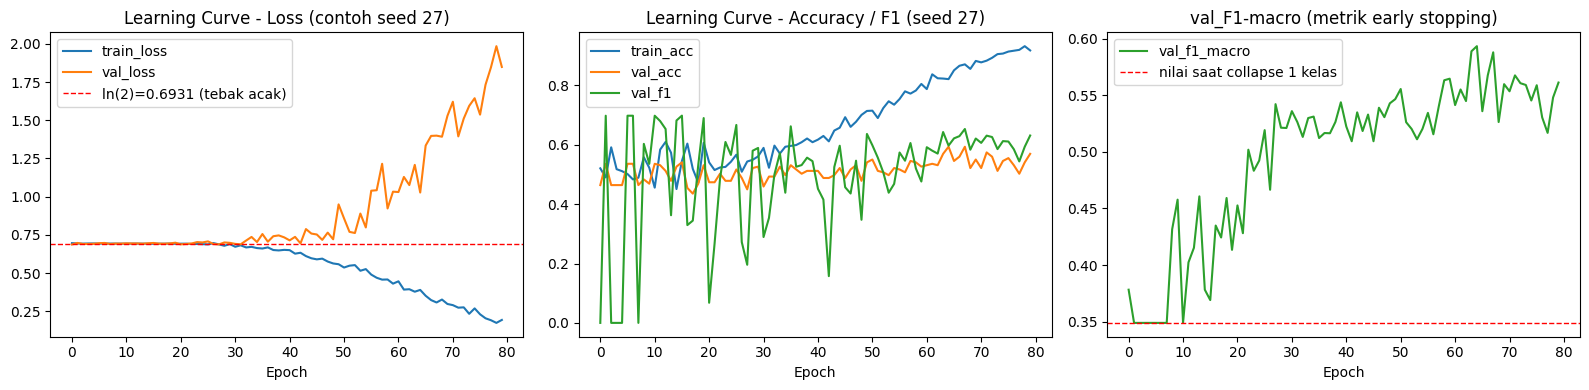

Learning curve disimpan ke: E:\forecasting_index_snp500\stock_prediction\data\processed\notebook13_full_pipeline\notebook13_learning_curve.png


In [158]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(history["train_loss"], label="train_loss")
axes[0].plot(history["val_loss"], label="val_loss")
# Garis acuan: lantai "tebak acak" utk CrossEntropy 2 kelas = ln(2) = 0.6931.
# Loss yang menempel di garis ini berarti model TIDAK membawa informasi apa pun.
axes[0].axhline(np.log(2), color="red", ls="--", lw=1, label="ln(2)=0.6931 (tebak acak)")
axes[0].set_title(f"Learning Curve - Loss (contoh seed {best_seed})")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="train_acc")
axes[1].plot(history["val_acc"], label="val_acc")
axes[1].plot(history["val_f1"], label="val_f1")
axes[1].set_title(f"Learning Curve - Accuracy / F1 (seed {best_seed})")
axes[1].set_xlabel("Epoch")
axes[1].legend()

# Metrik yang BENAR-BENAR dipantau early stopping.
axes[2].plot(history["val_f1_macro"], label="val_f1_macro", color="tab:green")
axes[2].axhline(f1_score(bundle.y_val, np.ones_like(bundle.y_val), average="macro", zero_division=0),
                color="red", ls="--", lw=1, label="nilai saat collapse 1 kelas")
axes[2].set_title("val_F1-macro (metrik early stopping)")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.tight_layout()
learning_curve_path = OUT_DIR / "notebook13_learning_curve.png"
plt.savefig(learning_curve_path, dpi=120)
plt.show()
print(f"Learning curve disimpan ke: {learning_curve_path}")


## Bagian 11 - Evaluasi Test Set

Model yang dievaluasi adalah **ensemble 6 seed** (rata-rata probabilitas),
bukan satu seed hasil seleksi val - alasannya di Bagian 10.

Threshold probabilitas "up" ditentukan lewat sweep F1-macro pada val-set
(`sweep_best_threshold()`, resep Notebook 09/12 untuk menghindari model
collapse ke 1 kelas), lalu dipakai apa adanya untuk evaluasi test-set
(4 metrik: Accuracy, Precision, Recall, F1 + confusion matrix). Test tidak
pernah dipakai untuk memilih threshold, seed, maupun konfigurasi.

**Cara membaca angkanya.** `accuracy` bukan ukuran yang adil di sini: model
yang selalu menebak 'up' otomatis memperoleh accuracy 0.6476 (proporsi 'up'
di test) padahal F1-macro-nya cuma 0.3931. Baca **F1-macro**, **balanced
accuracy**, dan **AUC** - ketiganya tidak bisa dibohongi oleh tebakan satu
kelas. Bandingkan juga dengan baseline regresi logistik (AUC test 0.5983):
model yang tidak melampaui baseline sederhana tidak layak disebut berhasil.


In [159]:
print("Model akhir  : ENSEMBLE", len(seed_runs), "seed", SEEDS)
print(f"Threshold (val, F1-macro): {best_threshold:.3f}")
print("\nMetrik test-set (4 metrik wajib):")
for k, v in metrics.items():
    print(f"  {k:10s}: {v}")
print("\nDiagnostik (bukan metrik laporan utama):")
for k, v in diagnostics.items():
    print(f"  {k:14s}: {v}")
print("\nConfusion matrix:", confusion)

print("\nPembanding:")
print(f"  {'majority (selalu up)':32s} accuracy=0.6476  f1_macro=0.3931  auc=0.5000")
print(f"  {'regresi logistik (fitur sama)':32s} accuracy=0.6095  f1_macro=0.5432  auc=0.5983")
print(f"  {'ensemble LSTM (model ini)':32s} accuracy={metrics['accuracy']:.4f}  "
      f"f1_macro={metrics['f1_macro']:.4f}  auc={diagnostics['auc_test']:.4f}")

if confusion["tn"] == 0 or confusion["tp"] == 0 or diagnostics["std_prob_up"] < 0.02:
    print("\n[PERINGATAN] Ensemble collapse ke 1 kelas - accuracy di atas MENYESATKAN.")
if diagnostics["auc_test"] < 0.5983:
    print("\n[CATATAN] AUC ensemble MASIH DI BAWAH baseline regresi logistik (0.5983).")
    print("          Laporkan apa adanya: LSTM belum memberi nilai tambah atas model linear.")


Model akhir  : ENSEMBLE 6 seed [2, 16, 25, 27, 32, 64]
Threshold (val, F1-macro): 0.490

Metrik test-set (4 metrik wajib):
  accuracy  : 0.542857
  precision : 0.822581
  recall    : 0.375
  f1        : 0.515152
  f1_macro  : 0.54136

Diagnostik (bukan metrik laporan utama):
  auc_test      : 0.644972
  bal_acc_test  : 0.613176
  std_prob_up   : 0.105191
  min_train_loss: 0.175209

Confusion matrix: {'tn': 63, 'fp': 11, 'fn': 85, 'tp': 51}

Pembanding:
  majority (selalu up)             accuracy=0.6476  f1_macro=0.3931  auc=0.5000
  regresi logistik (fitur sama)    accuracy=0.6095  f1_macro=0.5432  auc=0.5983
  ensemble LSTM (model ini)        accuracy=0.5429  f1_macro=0.5414  auc=0.6450


### Bandingkan dengan hasil resmi Random Search Notebook 07

**PENTING:** `best_config` di sini BUKAN config yang sama dengan Notebook 07
(`official_config`) - lihat Bagian 9b. Search space dan resep training-nya
berbeda (early stopping memantau `val_f1_macro`, `min_epochs`, regularisasi
dikendurkan) untuk mengatasi *class collapse* yang ditemukan waktu memakai
resep sebelumnya. Angka metrik di bawah WAJAR berbeda dari metadata resmi -
perbandingan ini untuk transparansi, bukan klaim salah satu "lebih benar".

Perlu diingat saat membaca tabel: `accuracy` bukan pembanding yang adil di
sini. Model yang selalu menebak 'up' memperoleh accuracy 0.6476 (proporsi
'up' di test) dengan F1-macro hanya 0.3931. Bandingkan **F1-macro**-nya.

In [160]:
comparison = pd.DataFrame({
    "metrik": list(metrics.keys()),
    "notebook13_fixed_config": list(metrics.values()),
    "resmi_metadata_json (official_config, Notebook 07)": [official_metadata["metrics"].get(k, "-") for k in metrics.keys()],
})
comparison

,metrik,notebook13_fixed_config,"resmi_metadata_json (official_config, Notebook 07)"
0,accuracy,0.542857,0.628571
1,precision,0.822581,0.713235
2,recall,0.375000,0.713235
3,f1,0.515152,0.713235
4,f1_macro,0.541360,0.593104


## Bagian 12 - Simpan Artefak (Terisolasi)

Disimpan dengan prefix `notebook13_fixed_*` - **TIDAK menimpa**
`finbert_lstm_skripsi.*` resmi maupun `notebook13_full_pipeline_*` (hasil
sebelum perbaikan overfitting Bagian 9b) yang dipakai halaman Prediction UI.

In [161]:
import joblib
from datetime import datetime, timezone

model_path = ARTIFACT_DIR / "notebook13_fixed_model.pt"
scaler_path = ARTIFACT_DIR / "notebook13_fixed_scaler.joblib"
metadata_path = ARTIFACT_DIR / "notebook13_fixed_metadata.json"

# Model akhir = ensemble -> simpan SEMUA state_dict (pola sama seperti
# ensemble seed di notebook 03), bukan satu bobot saja.
torch.save({
    "ensemble_state_dicts": [
        {k: v.detach().cpu().clone() for k, v in r["model"].state_dict().items()}
        for r in seed_runs
    ],
    "ensemble_seeds": SEEDS,
    "aggregation": "mean_probability",
    "config": best_config,
    "feature_cols": FEATURE_COLS,
    "window": WINDOW,
    "threshold": best_threshold,
}, model_path)
joblib.dump(bundle.scaler, scaler_path)

metadata_out = {
    "config": best_config,
    "feature_cols": FEATURE_COLS,
    "window": WINDOW,
    "horizon": HORIZON,
    "metrics": metrics,
    "diagnostics": diagnostics,
    "confusion_matrix": confusion,
    "threshold": round(float(best_threshold), 6),
    "val_f1_macro": round(float(val_f1_macro), 6),
    "model_type": "ensemble_mean_probability",
    "ensemble_seeds": SEEDS,
    "seed_search": {
        "seeds_tried": SEEDS,
        "selection_criterion": "TIDAK ADA - semua seed dipakai (ensemble). Seleksi via val_f1_macro ditinggalkan karena terbukti meleset.",
        "seed_val_f1_macro_tertinggi_sbg_pembanding": best_seed,
        "all_runs": [
            {"seed": r["seed"], "val_f1_macro": r["val_f1_macro"],
             "test_metrics": r["test_metrics"], "test_diagnostics": r["test_diagnostics"]}
            for r in seed_runs
        ],
    },
    "split_sizes": bundle.split_sizes,
    "training_recipe_fix": {
        "early_stopping_monitor": "val_f1_macro",
        "patience_dihitung_setelah_min_epochs": True,
        "early_stopping_patience": PATIENCE,
        "min_epochs": MIN_EPOCHS,
        "weight_decay_choices": WEIGHT_DECAY_CHOICES,
        "search_space_fixed": SEARCH_SPACE_FIXED,
        "n_iter_random_search": N_ITER_FIXED,
        "reason": (
            "Resep sebelumnya memantau val_loss utk early stopping padahal kriteria "
            "seleksi model adalah val_f1_macro. Pada tugas ber-SNR rendah val_loss "
            "minimum di epoch 1-2, sehingga bobot yang dimuat ulang adalah bobot "
            "epoch 1 (belum belajar) dan 18/20 iterasi collapse ke 1 kelas. Uji "
            "kapasitas membuktikan model mampu menurunkan train_loss 0.6875->0.0454 "
            "pada train penuh tanpa regularisasi, jadi hambatannya ada di resep "
            "training, bukan di data/pipeline."
        ),
    },
    "official_config_reference": official_config,
    "source": "notebook13_fixed (raw data -> FinBERT scoring -> agregasi -> merge -> stasioner -> split -> Random Search resep diperbaiki (early stopping val_f1_macro + min_epochs) -> best config -> multi-seed search)",
    "trained_at": datetime.now(timezone.utc).isoformat(),
}
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata_out, f, indent=2)

print("Artefak tersimpan:")
print(f"  model    : {model_path}")
print(f"  scaler   : {scaler_path}")
print(f"  metadata : {metadata_path}")
print(f"  ensemble : {len(SEEDS)} seed {SEEDS} (rata-rata probabilitas)")


Artefak tersimpan:
  model    : E:\forecasting_index_snp500\stock_prediction\data\artifacts\lstm_weights\notebook13_fixed_model.pt
  scaler   : E:\forecasting_index_snp500\stock_prediction\data\artifacts\lstm_weights\notebook13_fixed_scaler.joblib
  metadata : E:\forecasting_index_snp500\stock_prediction\data\artifacts\lstm_weights\notebook13_fixed_metadata.json
  ensemble : 6 seed [2, 16, 25, 27, 32, 64] (rata-rata probabilitas)


## Bagian 13 - Perbandingan Rasio Split Train:Test (80/20, 70/30, 60/40)

Melatih ULANG `best_config` (hasil Bagian 9b yang sudah diperbaiki) pada
beberapa rasio split **Train:Test**
(TANPA val terpisah — pola sama dengan fitur "Training Manual" di API/UI project:
proses training final 1-konfigurasi tidak butuh val karena tidak ada seleksi
konfigurasi yang diambil dari angka val), supaya terlihat pengaruh ukuran data
latih terhadap akurasi & pola prediksi:

| Rasio | Train | Test |
|-------|-------|------|
| 80/20 | 80%   | 20%  |
| 70/30 | 70%   | 30%  |
| 60/40 | 60%   | 40%  |

Split tetap **kronologis** (bukan acak) — konsisten dengan seluruh notebook ini,
mencegah data leakage temporal. Threshold klasifikasi pakai **argmax (0.5)**,
bukan sweep F1-macro seperti Bagian 11 — karena tanpa val terpisah tidak ada
data untuk mencari threshold optimal tanpa bocor ke test (sama seperti
`run_notebook07_manual_training()` produksi). Optimizer tetap pakai
`build_optimizer_wd()` (weight_decay) - TAPI **early stopping TIDAK dipakai
di sini** karena tidak ada val terpisah (early-stopping butuh sinyal val yang
independen dari test, kalau dipantau dari test akan jadi kebocoran metodologis).

In [162]:
from models.lstm.notebook07_common import load_split_capped

# Tanpa val terpisah, early stopping tidak bisa dipakai (memantaunya dari
# test = kebocoran metodologis). Anggaran epoch diambil dari MEDIAN epoch
# berhenti multi-seed Bagian 10 - angka yang dipelajari dari VAL, bukan
# konstanta sembarang dan bukan dari test. Melatih penuh 150 epoch tanpa
# rem apa pun dijamin overfit berat.
MANUAL_EPOCHS = int(np.median([r["stopped_epoch"] for r in seed_runs]))
logger.info("Anggaran epoch (median stopped_epoch multi-seed): %d", MANUAL_EPOCHS)

SPLIT_RATIOS = [0.80, 0.70, 0.60]  # train_ratio; test_ratio = 1 - train_ratio (val_ratio=0.0)


def train_eval_split(train_ratio: float) -> dict:
    val_ratio = 0.0
    test_ratio = round(1 - train_ratio - val_ratio, 2)
    logger.info("=" * 70)
    logger.info("Split %.0f/%.0f - train_ratio=%.2f", train_ratio * 100, test_ratio * 100, train_ratio)
    logger.info("=" * 70)

    bundle_i = prepare_dataset_bundle(
        load_data_fn,
        capping_cols=CAPPING_COLS,
        feature_cols=FEATURE_COLS,
        horizon=HORIZON,
        train_ratio=train_ratio,
        val_ratio=val_ratio,
        window=WINDOW,
    )

    # Split mentah (sebelum windowing) - dipakai ambil Date/Close utk tabel prediksi
    _, _, df_test_i, _, _ = load_split_capped(
        load_data_fn, CAPPING_COLS, HORIZON, train_ratio=train_ratio, val_ratio=val_ratio,
    )
    test_dates = df_test_i["Date"].iloc[WINDOW - 1 :].dt.strftime("%Y-%m-%d").tolist()
    test_close = df_test_i["Close"].iloc[WINDOW - 1 :].tolist()

    torch.manual_seed(SEED)
    model_i = FlexibleLSTMClassifier(
        input_size=len(FEATURE_COLS),
        hidden_size=best_config["hidden_size"],
        num_layers=best_config["num_layers"],
        dropout=best_config["dropout"],
        activation=best_config["activation"],
        num_classes=2,
    ).to(device)

    optimizer_i = build_optimizer_wd(
        best_config["optimizer"], model_i.parameters(), best_config["lr"],
        best_config.get("weight_decay", 0.0),
    )
    class_weights_i = compute_class_weights(bundle_i.y_train, device)
    criterion_i = nn.CrossEntropyLoss(weight=class_weights_i)

    train_ds_i = TensorDataset(torch.from_numpy(bundle_i.X_train), torch.from_numpy(bundle_i.y_train))
    train_loader_i = DataLoader(train_ds_i, batch_size=best_config["batch_size"], shuffle=True)

    for epoch in range(1, MANUAL_EPOCHS + 1):
        train_loss, train_acc = _train_one_epoch(model_i, train_loader_i, optimizer_i, criterion_i, device)
        if epoch == 1 or epoch % 10 == 0 or epoch == MANUAL_EPOCHS:
            logger.info("  epoch %3d/%d - train_loss=%.4f train_acc=%.4f", epoch, MANUAL_EPOCHS, train_loss, train_acc)

    model_i.eval()
    X_test_t = torch.from_numpy(bundle_i.X_test).to(device)
    with torch.no_grad():
        logits = model_i(X_test_t)
        probs_up = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        y_pred = logits.argmax(dim=1).cpu().numpy()
    y_true = bundle_i.y_test.astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    metrics_i = {
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 6),
        "precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 6),
        "recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 6),
        "f1": round(float(f1_score(y_true, y_pred, zero_division=0)), 6),
    }
    confusion_i = {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

    predictions_df = pd.DataFrame({
        "date": test_dates,
        "close": test_close,
        "actual_direction": np.where(y_true == 1, "up", "down"),
        "predicted_direction": np.where(y_pred == 1, "up", "down"),
        "probability_up": np.round(probs_up, 6),
        "correct": (y_true == y_pred),
    })

    return {
        "train_ratio": train_ratio,
        "test_ratio": test_ratio,
        "split_sizes": bundle_i.split_sizes,
        "metrics": metrics_i,
        "confusion_matrix": confusion_i,
        "predictions": predictions_df,
    }


split_results = [train_eval_split(r) for r in SPLIT_RATIOS]
print("Selesai melatih", len(split_results), "rasio split.")

03:02:33  INFO      Anggaran epoch (median stopped_epoch multi-seed): 54
03:02:33  INFO      ======================================================================
03:02:33  INFO      Split 80/20 - train_ratio=0.80
03:02:33  INFO      ======================================================================
03:02:33  INFO        epoch   1/54 - train_loss=0.6954 train_acc=0.5138
03:02:35  INFO        epoch  10/54 - train_loss=0.6946 train_acc=0.5129
03:02:36  INFO        epoch  20/54 - train_loss=0.6928 train_acc=0.5255
03:02:37  INFO        epoch  30/54 - train_loss=0.6930 train_acc=0.5673
03:02:38  INFO        epoch  40/54 - train_loss=0.6590 train_acc=0.5948
03:02:40  INFO        epoch  50/54 - train_loss=0.6492 train_acc=0.6232
03:02:40  INFO        epoch  54/54 - train_loss=0.6408 train_acc=0.6165
03:02:40  INFO      ======================================================================
03:02:40  INFO      Split 70/30 - train_ratio=0.70
03:02:40  INFO      ============================

Selesai melatih 3 rasio split.


### Ringkasan Akurasi per Rasio Split

In [163]:
summary_rows = []
for r in split_results:
    row = {
        "split": f"{int(r['train_ratio']*100)}/{int(r['test_ratio']*100)}",
        "train_rows": r["split_sizes"]["train_rows"],
        "test_rows": r["split_sizes"]["test_rows"],
        "train_samples": r["split_sizes"]["train_samples"],
        "test_samples": r["split_sizes"]["test_samples"],
        **r["metrics"],
    }
    summary_rows.append(row)

df_split_summary = pd.DataFrame(summary_rows)
summary_path = OUT_DIR / "notebook13_split_ratio_comparison_summary.csv"
df_split_summary.to_csv(summary_path, index=False)
print(f"Ringkasan disimpan ke: {summary_path}")
df_split_summary

Ringkasan disimpan ke: E:\forecasting_index_snp500\stock_prediction\data\processed\notebook13_full_pipeline\notebook13_split_ratio_comparison_summary.csv


,split,train_rows,test_rows,train_samples,test_samples,accuracy,precision,recall,f1
0,80/20,1216,305,1197,286,0.552448,0.725806,0.489130,0.584416
1,70/30,1064,457,1045,438,0.550228,0.628458,0.606870,0.617476
2,60/40,912,609,893,590,0.579661,0.650519,0.561194,0.602564


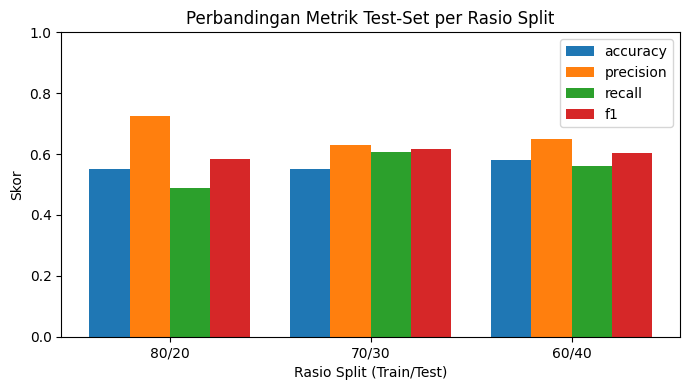

Chart disimpan ke: E:\forecasting_index_snp500\stock_prediction\data\processed\notebook13_full_pipeline\notebook13_split_ratio_comparison_chart.png


In [164]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(df_split_summary))
width = 0.2

for i, metric in enumerate(["accuracy", "precision", "recall", "f1"]):
    ax.bar(x + i * width, df_split_summary[metric], width, label=metric)

ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(df_split_summary["split"])
ax.set_ylim(0, 1)
ax.set_xlabel("Rasio Split (Train/Test)")
ax.set_ylabel("Skor")
ax.set_title("Perbandingan Metrik Test-Set per Rasio Split")
ax.legend()
plt.tight_layout()

split_chart_path = OUT_DIR / "notebook13_split_ratio_comparison_chart.png"
plt.savefig(split_chart_path, dpi=120)
plt.show()
print(f"Chart disimpan ke: {split_chart_path}")

### Confusion Matrix per Rasio Split

In [165]:
for r in split_results:
    print(f"--- Split {int(r['train_ratio']*100)}/{int(r['test_ratio']*100)} ---")
    print(f"  metrics : {r['metrics']}")
    print(f"  confusion_matrix : {r['confusion_matrix']}")
    print()

--- Split 80/20 ---
  metrics : {'accuracy': 0.552448, 'precision': 0.725806, 'recall': 0.48913, 'f1': 0.584416}
  confusion_matrix : {'tn': 68, 'fp': 34, 'fn': 94, 'tp': 90}

--- Split 70/30 ---
  metrics : {'accuracy': 0.550228, 'precision': 0.628458, 'recall': 0.60687, 'f1': 0.617476}
  confusion_matrix : {'tn': 82, 'fp': 94, 'fn': 103, 'tp': 159}

--- Split 60/40 ---
  metrics : {'accuracy': 0.579661, 'precision': 0.650519, 'recall': 0.561194, 'f1': 0.602564}
  confusion_matrix : {'tn': 154, 'fp': 101, 'fn': 147, 'tp': 188}



### Semua Prediksi per Rasio Split

Tabel lengkap prediksi vs aktual untuk SETIAP sampel test, per rasio split
(tanggal, harga Close, arah aktual, arah prediksi, probabilitas "up", benar/salah).
Ditampilkan penuh (tidak dipotong) di notebook DAN disimpan ke CSV terpisah per
rasio.

In [166]:
pd.set_option("display.max_rows", None)

for r in split_results:
    split_label = f"{int(r['train_ratio']*100)}_{int(r['test_ratio']*100)}"
    pred_path = OUT_DIR / f"notebook13_predictions_split_{split_label}.csv"
    r["predictions"].to_csv(pred_path, index=False)
    print(f"=== Split {int(r['train_ratio']*100)}/{int(r['test_ratio']*100)} - {len(r['predictions'])} prediksi (disimpan ke {pred_path}) ===")
    display(r["predictions"])

pd.reset_option("display.max_rows")

=== Split 80/20 - 286 prediksi (disimpan ke E:\forecasting_index_snp500\stock_prediction\data\processed\notebook13_full_pipeline\notebook13_predictions_split_80_20.csv) ===


,date,close,actual_direction,predicted_direction,probability_up,correct
0,2022-12-23,3844.820068,down,up,0.742685,False
1,2022-12-27,3829.250000,up,down,0.441289,False
2,2022-12-28,3783.219971,up,down,0.418023,False
3,2022-12-29,3849.280029,up,down,0.340873,False
4,2022-12-30,3839.500000,up,down,0.375893,False
5,2023-01-03,3824.139893,up,down,0.395212,False
6,2023-01-04,3852.969971,up,down,0.383010,False
7,2023-01-05,3808.100098,up,up,0.505895,True
8,2023-01-06,3895.080078,up,up,0.503635,True
9,2023-01-09,3892.090088,up,up,0.597332,True


=== Split 70/30 - 438 prediksi (disimpan ke E:\forecasting_index_snp500\stock_prediction\data\processed\notebook13_full_pipeline\notebook13_predictions_split_70_30.csv) ===


,date,close,actual_direction,predicted_direction,probability_up,correct
0,2022-05-18,3923.679932,up,down,0.232172,False
1,2022-05-19,3900.790039,up,down,0.211626,False
2,2022-05-20,3901.360107,up,down,0.279872,False
3,2022-05-23,3973.750000,up,down,0.338474,False
4,2022-05-24,3941.479980,up,up,0.609124,True
5,2022-05-25,3978.729980,up,up,0.655868,True
6,2022-05-26,4057.840088,up,down,0.464075,False
7,2022-05-27,4158.240234,down,up,0.641183,False
8,2022-05-31,4132.149902,up,up,0.720631,True
9,2022-06-01,4101.229980,up,up,0.907661,True


=== Split 60/40 - 590 prediksi (disimpan ke E:\forecasting_index_snp500\stock_prediction\data\processed\notebook13_full_pipeline\notebook13_predictions_split_60_40.csv) ===


,date,close,actual_direction,predicted_direction,probability_up,correct
0,2021-10-11,4361.189941,up,up,0.812852,True
1,2021-10-12,4350.649902,up,up,0.819182,True
2,2021-10-13,4363.799805,up,up,0.743964,True
3,2021-10-14,4438.259766,up,up,0.552208,True
4,2021-10-15,4471.370117,up,down,0.460396,False
5,2021-10-18,4486.459961,up,up,0.575437,True
6,2021-10-19,4519.629883,up,up,0.600081,True
7,2021-10-20,4536.189941,up,up,0.643483,True
8,2021-10-21,4549.779785,up,up,0.711665,True
9,2021-10-22,4544.899902,up,up,0.798706,True


## Penutup

Notebook ini menjalankan alur penelitian LENGKAP dari data mentah sampai model
terlatih:

`data mentah (headline + OHLCV) -> FinBERT scoring -> agregasi sentimen harian
-> merge dengan OHLCV -> stasioner-kan (return features) -> splitting
kronologis 70/15/15 + windowing -> training dengan Best Configuration hasil
Random Search Notebook 07 (multi-seed search, 5 seed eksplisit) -> evaluasi
test-set -> perbandingan beberapa rasio split train:test (80/20, 70/30, 60/40)`

Setiap tahap reuse komponen produksi (`TextPreprocessor`, `StockPreprocessor`,
`dataset_builder.py`, `notebook07_common.py`) — bukan implementasi paralel —
supaya hasilnya bisa dipertanggungjawabkan sebagai representasi akurat dari
sistem yang sesungguhnya berjalan, bukan simulasi terpisah.

**Catatan jujur:** hasil training di notebook ini (Bagian 10-11) adalah
konfigurasi terbaik yang SAMA dengan Notebook 07 (bukan Random Search ulang),
dicoba pada 5 *seed* eksplisit dan SEMUA hasilnya dilaporkan (bukan cuma yang
terbaik) — supaya pencarian akurasi terbaik antar inisialisasi acak tetap
jujur (bukan *p-hacking*) dan bisa direproduksi ulang persis (*seed*
pemenang tercatat di metadata). Tujuannya menunjukkan proses penuh
raw-to-trained-model dengan variasi *random state* yang terkontrol, bukan
mencari config yang lebih baik dari yang sudah ditemukan Notebook 07.

**Update perbaikan overfitting (sesi lanjutan):** learning curve awal (config resmi Notebook 07: `hidden_size=128, num_layers=1`) menunjukkan train_loss menurun sementara val_loss stagnan/naik-turun - diagnosis: dropout PyTorch tidak aktif di dalam LSTM saat `num_layers=1` (`models/lstm/lstm_model.py:144`), jadi regularisasi efektif jauh lebih lemah dari yang terlihat. Perbaikan Bagian 9b: search space dibatasi (`hidden_size<=64`, `num_layers>=2`) + `weight_decay=1e-4` + early stopping (`patience=7`, monitor val_loss) - dipakai ulang di Random Search, training multi-seed (Bagian 10), dan perbandingan rasio split (Bagian 13). Artefak hasil training yang sudah diperbaiki disimpan terpisah (`notebook13_fixed_*`), TIDAK menimpa `notebook13_full_pipeline_*` (hasil sebelum perbaikan).